# Malaria Cell Classification: can a network spot the parasite, and can we trust the score?

**The question:** a blood smear under a microscope is a sea of red cells, and a technician has to find the few that hide a malaria parasite. A neural network that looks at one cell and says "infected" or "not" could speed that up. It does it well on this data (about 97% right), but the headline number hides better questions. *What does the network actually see, do simple colour statistics already do most of the job, does the usual train/test split flatter the score, how much data is enough, and where does it fail?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. H1: do infected cells look different?
6. Splitting the cells safely
7. H2: how far do simple colour statistics get?
8. H3: do neural networks beat the baseline?
9. H4: does the usual random split inflate the score?
10. H5: how much data do we need?
11. H6: choosing a threshold, and where it fails
12. Takeaways
13. Limitations

**Run it:** `uv run jupyter lab DL/malaria-cell-classification/malaria_cell_classification.ipynb`, or *Run All* in any Jupyter. The images (about 350 MB, from the US National Library of Medicine) download themselves on the first run. It uses a GPU if present and takes about 40 minutes on one.

## 1. 💡 The simple analogy

Imagine a **lab technician looking for a tiny purple speck inside a pink disc**. Healthy red blood cells are smooth pink discs; an infected one has a small dark stain, the parasite, tucked inside.

- A **colour-summary model** is a technician who only looks at how dark and purple the whole disc is, without looking at the shape of anything inside. Surprisingly, that already works well.
- A **convolutional network** is a technician with a magnifying glass who learns to recognise the speck itself, wherever it is on the cell.
- **Pretraining** is hiring a technician who has already looked at a million photos of everyday things: they know what edges and blobs look like, so they only need to learn what *this* speck looks like.
- A **leaky split** is like quizzing the technician on cells from the *same slide* they trained on: they might recognise the slide's lighting rather than the parasite. An **honest split** quizzes them on slides they have never seen.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the image size and the training budget keeps the notebook reproducible and avoids "magic numbers". With the seeds fixed (and the GPU set to deterministic mode), every model comes out the same each time you run it.

In [1]:
import urllib.request
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
import torchvision
from PIL import Image
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from torch import nn

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
DATA_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/cell_images.zip"
SEED = 365
SIZE = 96  # every cell is resized to SIZE x SIZE pixels
N_BOOTSTRAP = 2_000
N_SEEDS = 5  # trainings per setting (fewer for the larger network, see below)
N_SEEDS_RESNET = 3
BATCH = 128
EPOCHS_SMALL = 12
EPOCHS_RESNET = 6
LEARNING_RATE = 1e-3
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU
torch.backends.cudnn.benchmark = False
sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* load the NIH malaria cell images (single red blood cells, cut out from thin blood smear slides, each labelled **parasitized** or **uninfected** by experts), shrink each to 96 x 96 pixels, and find out which **slide** every cell came from (the slide is in the file name). *Why:* before training we should know the class balance, how many cells share a slide, and whether anything in the image *other than the parasite* could give the answer away, such as the size of the picture.

> **Problems in the legacy notebooks and app this replaces:** the notebook used Colab-only paths (`/content/drive/...`), a random cell-level split, 100 epochs of training with unshuffled batches, and one accuracy with no baseline. The Flask app used a different model (VGG19 from a tutorial) whose **prediction messages said "Infected With Pneumonia"** (copied from a different project), and it wrote every uploaded file to disk. Both relied on `.h5` model files that are not in the repository. Everything is rebuilt here in PyTorch with a download script instead of copied data.

In [2]:
def load_cells() -> pd.DataFrame:
    """Loads every cell image, resized and cached, with its label, slide and original size.

    The NIH archive (about 350 MB) is downloaded into ``data/`` once. The resized images are
    cached in ``data/cells_{SIZE}.npz`` so later runs start in seconds.

    Returns:
        One row per cell with columns ``path``, ``infected`` (1 = parasitized), ``slide``,
        ``width`` and ``height`` (original pixels). The resized pixels are returned separately
        in the module-level array ``PIXELS``.

    Raises:
        ValueError: If a file name does not follow the ``<slide>_IMG_...`` pattern.
    """
    root = DATA_DIR / "cell_images"
    if not root.exists():
        archive = DATA_DIR / "cell_images.zip"
        if not archive.exists():
            urllib.request.urlretrieve(DATA_URL, archive)
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(DATA_DIR)
    records = []
    for label, folder in [(1, "Parasitized"), (0, "Uninfected")]:
        for path in sorted((root / folder).glob("*.png")):
            if "_IMG" not in path.name:
                raise ValueError(f"Unexpected file name: {path.name}")
            records.append((str(path), label, path.name.split("_IMG")[0]))
    table = pd.DataFrame(records, columns=["path", "infected", "slide"])

    def read(path: str) -> tuple[np.ndarray, int, int]:
        with Image.open(path) as im:
            width, height = im.size
            return np.asarray(im.convert("RGB").resize((SIZE, SIZE), Image.BILINEAR)), width, height

    cache = DATA_DIR / f"cells_{SIZE}.npz"
    if cache.exists():
        stored = np.load(cache)
        pixels, widths, heights = stored["pixels"], stored["widths"], stored["heights"]
    else:
        with ThreadPoolExecutor(8) as pool:
            decoded = list(pool.map(read, table["path"]))
        pixels = np.stack([d[0] for d in decoded])
        widths = np.array([d[1] for d in decoded])
        heights = np.array([d[2] for d in decoded])
        np.savez(cache, pixels=pixels, widths=widths, heights=heights)
    table["width"], table["height"] = widths, heights
    global PIXELS
    PIXELS = pixels
    return table


cells = load_cells()
labels = cells["infected"].to_numpy()
slides = cells["slide"].to_numpy()
per_slide = cells.groupby("slide")["infected"].agg(["size", "mean"])
mixed = ((per_slide["mean"] > 0) & (per_slide["mean"] < 1)).sum()
print(f"{len(cells):,} cells: {labels.sum():,} parasitized and {(labels == 0).sum():,} uninfected")
print(
    f"They come from {len(per_slide)} slides ({mixed} slides hold both kinds of cell, "
    f"{(per_slide['mean'] == 0).sum()} hold only uninfected cells, "
    f"{(per_slide['mean'] == 1).sum()} only parasitized)"
)
biggest = per_slide["size"].max()
print(
    f"Cells per slide: median {per_slide['size'].median():.0f}, "
    f"largest slide {biggest} ({biggest / len(cells):.1%} of all cells)"
)
print(f"Always guessing 'parasitized' scores {labels.mean():.1%}")
print(
    f"Original image size: width median {cells['width'].median():.0f} "
    f"(range {cells['width'].min()} to {cells['width'].max()}), "
    f"height median {cells['height'].median():.0f}"
)

27,558 cells: 13,779 parasitized and 13,779 uninfected
They come from 201 slides (151 slides hold both kinds of cell, 50 hold only uninfected cells, 0 only parasitized)
Cells per slide: median 85, largest slide 702 (2.5% of all cells)
Always guessing 'parasitized' scores 50.0%
Original image size: width median 130 (range 46 to 394), height median 130


**How to read this:**

- **27,558 cells, perfectly balanced:** 13,779 parasitized and 13,779 uninfected. Always guessing "parasitized" scores **50.0%**.
- **201 slides:** **151** slides hold both kinds of cell (an infected patient has plenty of healthy cells too) and **50** hold only uninfected cells (healthy patients). The median slide gives **85** cells, and the biggest slide **702** (2.5% of all cells). This is the structure that makes a random split risky: cells from one slide share the same stain, lighting and camera.
- **The images come in different sizes:** the original width runs from 46 to 394 pixels (median 130) and the height has a median of 130. A shortcut based on image size is something we should rule out (H1).

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Do infected cells differ in colour or size? | Same distribution | They differ | Mann-Whitney U per feature, Holm correction, Cliff's δ |
| H2 | Do simple colour statistics beat guessing? | Accuracy = share of the larger class | Higher | Gradient boosting on 21 colour statistics, AUC and accuracy on held-out slides |
| H3 | Does a pretrained network beat a small CNN, and both the baseline? | Equal accuracy | Differs | 3 to 5 seeds, Mann-Whitney U; exact McNemar on the same test cells |
| H4 | Does a random cell split flatter the score compared with a split by slide? | Equal accuracy | Random split is higher | Paired runs, same recipe, Wilcoxon |
| H5 | Does more training data keep helping? | Same accuracy at every size | Increases | 500, 2,000, 8,000 and all 16,319 cells; 3 seeds each |
| H6 | Is the error rate the same on every slide? | Same error rate everywhere | Differs | Chi-square test of homogeneity across test slides |

*Why these tests?* Colour values are skewed, so rank-based tests (Mann-Whitney, Wilcoxon) are safer than t-tests. With 27,558 cells nearly everything is statistically significant, so we always report the **effect size** (Cliff's δ: +1 = always higher, -1 = always lower). McNemar's test is exact for comparing two classifiers on the same test cells. Holm's correction handles the five H1 comparisons at once.

## 5. H1: do infected cells look different?

*What:* for every cell we measure the average red, green and blue values of the cell itself (ignoring the black background), the size of the original picture, and the share of the image the cell fills. We compare parasitized and uninfected cells with Mann-Whitney tests, correct for five tests with Holm's method, and report Cliff's δ and the AUC of each feature used alone. *Why:* it tells us what a very simple detector could use, and whether picture size is a shortcut.

In [3]:
mask = PIXELS.max(axis=3) > 20  # cells sit on a black background: keep only the cell itself
flat = PIXELS.reshape(len(PIXELS), -1, 3).astype(np.float32)
mflat = mask.reshape(len(PIXELS), -1)
counts = np.maximum(mflat.sum(axis=1), 1)
channel_means = np.stack([(flat[:, :, c] * mflat).sum(axis=1) / counts for c in range(3)], axis=1)
features = pd.DataFrame(
    {
        "red mean": channel_means[:, 0],
        "green mean": channel_means[:, 1],
        "blue mean": channel_means[:, 2],
        "cell area (pixels in the image)": cells["width"] * cells["height"],
        "share of image that is cell": mflat.mean(axis=1),
    }
)
rows = []
for name in features:
    a, b = features.loc[labels == 1, name], features.loc[labels == 0, name]
    test = stats.mannwhitneyu(a, b)
    rows.append(
        {
            "feature": name,
            "parasitized median": a.median(),
            "uninfected median": b.median(),
            "p": test.pvalue,
            "cliffs_delta": 2 * test.statistic / (len(a) * len(b)) - 1,
        }
    )
h1 = pd.DataFrame(rows).set_index("feature")
h1["p_holm"] = multipletests(h1["p"], method="holm")[1]
pd.options.display.float_format = "{:,.3g}".format
print(h1.to_string())
pd.reset_option("display.float_format")
single = {name: roc_auc_score(labels, features[name]) for name in features}
print("\nAUC of each feature on its own (0.5 = useless, flipped if below 0.5):")
for name, auc in single.items():
    print(f"  {name}: {max(auc, 1 - auc):.3f}")

                                 parasitized median  uninfected median         p  cliffs_delta    p_holm
feature                                                                                                 
red mean                                        190                185  0.000641        0.0237  0.000641
green mean                                      143                154         0        -0.382         0
blue mean                                       148                156 7.29e-257        -0.238 2.91e-256
cell area (pixels in the image)            1.77e+04           1.72e+04  2.06e-24        0.0709  4.13e-24
share of image that is cell                    0.74              0.754 2.06e-106        -0.152 6.19e-106

AUC of each feature on its own (0.5 = useless, flipped if below 0.5):
  red mean: 0.512
  green mean: 0.691
  blue mean: 0.619
  cell area (pixels in the image): 0.535
  share of image that is cell: 0.576


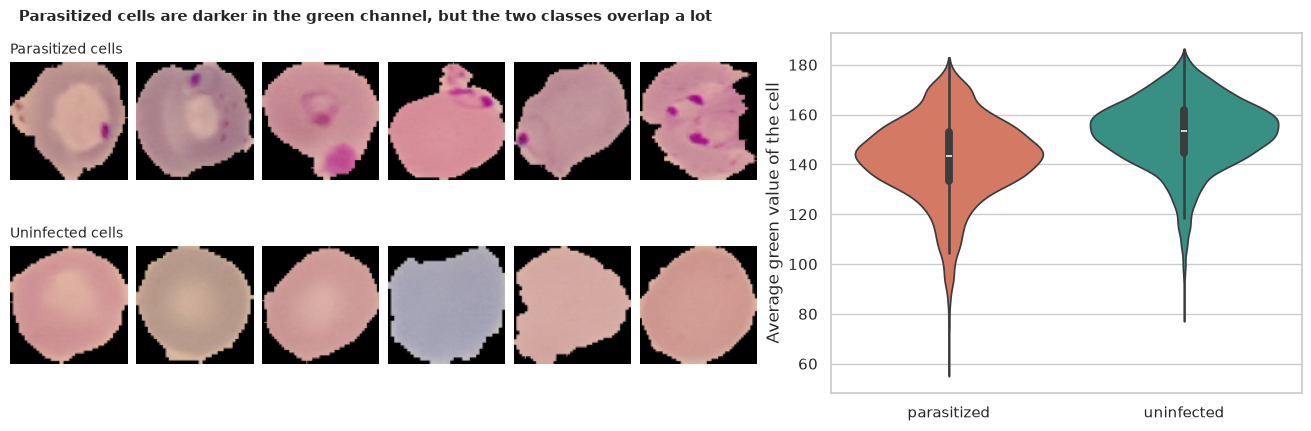

In [4]:
show = {1: np.flatnonzero(labels == 1), 0: np.flatnonzero(labels == 0)}
picked = {k: rng.choice(v, 6, replace=False) for k, v in show.items()}
fig = plt.figure(figsize=(13, 4.2), layout="constrained")
grid = fig.add_gridspec(2, 10)
for row, label in enumerate([1, 0]):
    for col in range(6):
        ax = fig.add_subplot(grid[row, col])
        ax.imshow(PIXELS[picked[label][col]])
        ax.axis("off")
        if col == 0:
            ax.set_title(
                "Parasitized cells" if label == 1 else "Uninfected cells", loc="left", fontsize=10
            )
ax = fig.add_subplot(grid[:, 6:])
plot_df = pd.DataFrame(
    {
        "green mean": features["green mean"],
        "class": np.where(labels == 1, "parasitized", "uninfected"),
    }
)
sns.violinplot(
    data=plot_df,
    x="class",
    y="green mean",
    hue="class",
    palette=[ORANGE, TEAL],
    order=["parasitized", "uninfected"],
    ax=ax,
    legend=False,
    cut=0,
)
ax.set_ylabel("Average green value of the cell")
ax.set_xlabel("")
fig.suptitle(
    "Parasitized cells are darker in the green channel, but the two classes overlap a lot",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "01_cells.png", dpi=150)
plt.show()

**How to read this:**

- **Parasitized cells are darker in green:** median green **143** against **154** for uninfected cells, Cliff's δ = **-0.382** (a medium effect) and an AUC of **0.691** for that feature alone. Blue is also lower (δ = -0.238, AUC 0.619). The parasite's purple stain absorbs green light. **We reject H₀** for these (Holm-adjusted p far below 0.001).
- **Red barely moves:** δ = **0.024**. The difference is statistically significant with this many cells but practically nothing.
- **There is no picture-size shortcut:** the original image area has δ = **0.071** and an AUC of only **0.535** alone, and the share of the image the cell fills has δ = -0.152 (AUC 0.576). Image size does carry a faint trace of the class, but nowhere near enough to explain a 97% score.
- **The classes overlap a lot** on any single colour feature (the violin plot): the best single feature, green, has an AUC of 0.69. Seeing the parasite itself needs more than average colour.

## 6. Splitting the cells safely

*What:* two ways to divide the cells into training (60%), validation (20%) and test (20%):

- **The honest split:** hand out whole **slides** so that no slide appears in two parts. This tests what we care about: does the model work on a patient's slide it has never seen?
- **The random split:** shuffle all cells together, as the legacy notebook did, with the same sizes as the honest split. Cells from the same slide end up on both sides.

*Why:* with 85 cells per slide on average, a model can pick up slide-specific clues (stain strength, lighting). If so, the random split would flatter it. H4 tests exactly that.

In [5]:
def slide_split(
    train_share: float = 0.6, val_share: float = 0.2, seed: int = SEED
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Splits cells into train, validation and test sets so that no slide appears in two of them.

    Slides are shuffled and handed out until each set holds about its share of the cells.

    Args:
        train_share: Fraction of cells for training.
        val_share: Fraction of cells for validation (the rest is the test set).
        seed: Seed for the shuffle.

    Returns:
        Index arrays for the training, validation and test cells.
    """
    order = np.random.default_rng(seed).permutation(per_slide.index.to_numpy())
    sizes = per_slide.loc[order, "size"].to_numpy().cumsum() / len(cells)
    bucket = np.where(sizes <= train_share, 0, np.where(sizes <= train_share + val_share, 1, 2))
    slide_bucket = dict(zip(order, bucket, strict=True))
    which = np.array([slide_bucket[s] for s in slides])
    return tuple(np.flatnonzero(which == b) for b in range(3))


def random_split(n_train: int, n_val: int, seed: int = SEED) -> tuple[np.ndarray, ...]:
    """The "leaky" split: cells are shuffled regardless of the slide they came from.

    Args:
        n_train: Number of training cells (matched to the slide split).
        n_val: Number of validation cells.
        seed: Seed for the shuffle.

    Returns:
        Index arrays for the training, validation and test cells.
    """
    order = np.random.default_rng(seed).permutation(len(cells))
    return order[:n_train], order[n_train : n_train + n_val], order[n_train + n_val :]


train_idx, val_idx, test_idx = slide_split()
leaky_train, leaky_val, leaky_test = random_split(len(train_idx), len(val_idx))
for name, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    print(
        f"Slide split, {name}: {len(idx):,} cells from {len(set(slides[idx]))} slides, "
        f"{labels[idx].mean():.1%} parasitized"
    )
assert not set(slides[train_idx]) & set(slides[test_idx])
shared = len(set(slides[leaky_train]) & set(slides[leaky_test]))
print(
    f"Random split: {shared} of the {len(set(slides[leaky_test]))} test slides also appear in "
    "the training set"
)

Slide split, train: 16,319 cells from 114 slides, 52.1% parasitized
Slide split, validation: 5,646 cells from 45 slides, 44.9% parasitized
Slide split, test: 5,593 cells from 42 slides, 48.9% parasitized
Random split: 201 of the 201 test slides also appear in the training set


**How to read this:**

- **The honest split** gives **16,319** training cells (114 slides), **5,646** validation cells (45 slides) and **5,593** test cells (42 slides). The class mix differs a little between parts because the 50 healthy-only slides land wherever they land: **52.1%** parasitized in training, **44.9%** in validation and **48.9%** in test.
- **The random split** is leaky by construction: **all 201 slides** that appear in the test cells also appear in the training cells.

## 7. H2: how far do simple colour statistics get?

*What:* a baseline with **no neural network**: for each cell, 21 colour statistics (mean, spread and five percentiles of each of the red, green and blue values of the cell), fed to a gradient-boosting classifier trained on the honest training slides and scored on the held-out slides. *Why:* every neural network should have to beat a simple, strong baseline; if it does not, the extra complexity is not earning its keep.

In [6]:
def cell_features(indices: np.ndarray) -> np.ndarray:
    """Simple colour summaries of each cell: mean, spread and percentiles of every channel.

    Args:
        indices: Which cells to describe.

    Returns:
        A matrix with one row per cell.
    """
    out = []
    for i in indices:
        px = PIXELS[i][mask[i]]
        if len(px) == 0:
            px = PIXELS[i].reshape(-1, 3)
        stats_per_channel = [px.mean(0), px.std(0), *np.percentile(px, [5, 25, 50, 75, 95], axis=0)]
        out.append(np.concatenate(stats_per_channel))
    return np.array(out)


def sensitivity_at_specificity(
    y_true: np.ndarray, score: np.ndarray, threshold_scores: np.ndarray, specificity: float
) -> tuple[float, float, float]:
    """Sensitivity of a detector whose threshold keeps ``specificity`` on a calibration sample.

    Args:
        y_true: Test labels (1 = infected).
        score: Test scores (higher = more likely infected).
        threshold_scores: Scores of known-uninfected cells from a separate validation set.
        specificity: Wanted share of uninfected cells that stay unflagged.

    Returns:
        The sensitivity on the test cells and its 95% Wilson interval.
    """
    threshold = np.quantile(threshold_scores, specificity)
    flagged = score[y_true == 1] > threshold
    low, high = proportion_confint(int(flagged.sum()), len(flagged), method="wilson")
    return float(flagged.mean()), float(low), float(high)


baseline = HistGradientBoostingClassifier(random_state=SEED).fit(
    cell_features(train_idx), labels[train_idx]
)
base_test_score = baseline.predict_proba(cell_features(test_idx))[:, 1]
base_val_score = baseline.predict_proba(cell_features(val_idx))[:, 1]
base_auc = roc_auc_score(labels[test_idx], base_test_score)
base_acc = ((base_test_score > 0.5) == labels[test_idx]).mean()
print(
    f"Colour-summary baseline on the held-out slides: AUC {base_auc:.3f}, "
    f"accuracy {base_acc:.1%} (always guessing the majority class: "
    f"{max(labels[test_idx].mean(), 1 - labels[test_idx].mean()):.1%})"
)

Colour-summary baseline on the held-out slides: AUC 0.978, accuracy 93.2% (always guessing the majority class: 51.1%)


**How to read this:**

- **The colour baseline is strong:** on the held-out slides it reaches an **AUC of 0.978** and **93.2% accuracy**, against **51.1%** for always guessing the larger class. **We reject H₀** by a huge margin.
- This is much better than any single feature (green alone: AUC 0.691): it is the *combination* of spread and percentiles of the colours, which captures "a dark purple spot inside an otherwise pink cell", not just the average darkness.
- So the question for the network in H3 is not "can it beat guessing" but "can it beat 93.2%".

## 8. H3: do neural networks beat the baseline?

*What:* two networks, both trained from the honest training slides and judged on the held-out slides:

1. **A small CNN** (three convolution blocks and global pooling, about 94,000 weights), a modern version of the legacy notebook's small network.
2. **ResNet-18**, pretrained on ImageNet and fine-tuned.

Both use random flips as augmentation (cells have no "up"), AdamW with a one-cycle learning rate, and are judged on the **final epoch** (the test cells never choose anything). The small CNN is trained 5 times and ResNet 3 times (it is slower). We compare with an **exact McNemar test** on the same test cells (seed 0) and a Mann-Whitney test over seeds.

In [7]:
def to_input(batch: torch.Tensor) -> torch.Tensor:
    """Turns uint8 images (batch, H, W, 3) into normalised float tensors (batch, 3, H, W)."""
    x = batch.permute(0, 3, 1, 2).float().div(255)
    return (x - IMAGENET_MEAN.to(x.device)) / IMAGENET_STD.to(x.device)


def augment(x: torch.Tensor) -> torch.Tensor:
    """Random flips and a random transpose per image (cells have no up or down).

    Args:
        x: Batch of images, shape (batch, 3, H, W).

    Returns:
        The augmented batch.
    """
    n = len(x)
    flip_h = torch.rand(n, device=x.device) < 0.5
    flip_v = torch.rand(n, device=x.device) < 0.5
    swap = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip_h[:, None, None, None], x.flip(3), x)
    x = torch.where(flip_v[:, None, None, None], x.flip(2), x)
    return torch.where(swap[:, None, None, None], x.transpose(2, 3), x)


class SmallCNN(nn.Module):
    """A small convolutional network in the spirit of the legacy notebook, without its flaws.

    Three blocks of convolution, batch norm, ReLU and pooling, then global average pooling.
    """

    def __init__(self) -> None:
        super().__init__()
        blocks, width = [], 3
        for out in (32, 64, 128):
            blocks += [
                nn.Conv2d(width, out, 3, padding=1),
                nn.BatchNorm2d(out),
                nn.ReLU(),
                nn.MaxPool2d(2),
            ]
            width = out
        self.features = nn.Sequential(
            *blocks, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3)
        )
        self.head = nn.Linear(width, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """One score per image (a positive score means "infected")."""
        return self.head(self.features(x)).squeeze(1)


def make_resnet() -> nn.Module:
    """ResNet-18 pretrained on ImageNet, with a one-score head for infected vs not."""
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
    net = torchvision.models.resnet18(weights=weights)
    net.fc = nn.Sequential(nn.Linear(net.fc.in_features, 1), nn.Flatten(0))  # one score per image
    return net


def train_cell_model(kind: str, train_indices: np.ndarray, seed: int) -> nn.Module:
    """Trains a cell classifier for a fixed number of epochs (the test cells are never used).

    Args:
        kind: ``"small"`` for the small CNN or ``"resnet"`` for the pretrained ResNet-18.
        train_indices: Cells to train on.
        seed: Seed for weights and batch order.

    Returns:
        The trained network in evaluation mode.
    """
    torch.manual_seed(seed)
    model = (SmallCNN() if kind == "small" else make_resnet()).to(DEVICE)
    epochs = EPOCHS_SMALL if kind == "small" else EPOCHS_RESNET
    lr = LEARNING_RATE if kind == "small" else 3e-4
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(train_indices) / BATCH))
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=steps)
    images = torch.tensor(PIXELS[train_indices], device=DEVICE)
    targets = torch.tensor(labels[train_indices], device=DEVICE).float()
    for _ in range(epochs):
        model.train()
        order = torch.randperm(len(images), device=DEVICE)
        for start in range(0, len(images), BATCH):
            pick = order[start : start + BATCH]
            loss = F.binary_cross_entropy_with_logits(
                model(augment(to_input(images[pick]))), targets[pick]
            )
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
    return model.eval()


def score_cells(model: nn.Module, indices: np.ndarray) -> np.ndarray:
    """Scores (higher = more likely infected) for the given cells.

    Args:
        model: A trained classifier.
        indices: Which cells to score.

    Returns:
        One score per cell.
    """
    out = []
    with torch.no_grad():
        for start in range(0, len(indices), 1024):
            batch = torch.tensor(PIXELS[indices[start : start + 1024]], device=DEVICE)
            out.append(model(to_input(batch)).cpu().numpy())
    return np.concatenate(out)


def summarise(score: np.ndarray, indices: np.ndarray) -> dict[str, float]:
    """AUC and accuracy (at score 0) of a set of test scores.

    Args:
        score: Model scores for the cells.
        indices: The cells those scores belong to.

    Returns:
        A dict with ``auc`` and ``accuracy``.
    """
    return {
        "auc": roc_auc_score(labels[indices], score),
        "accuracy": float(((score > 0) == labels[indices]).mean()),
    }


results = []
test_scores = {}
val_scores_store = {}
for kind, n_runs in [("small", N_SEEDS), ("resnet", N_SEEDS_RESNET)]:
    for seed in range(n_runs):
        model = train_cell_model(kind, train_idx, seed)
        score = score_cells(model, test_idx)
        test_scores[(kind, seed)] = score
        if seed == 0:
            val_scores_store[kind] = score_cells(model, val_idx)
        results.append({"model": kind, "seed": seed, **summarise(score, test_idx)})
model_results = pd.DataFrame(results)
summary = model_results.groupby("model").agg(
    runs=("seed", "size"),
    auc_mean=("auc", "mean"),
    auc_sd=("auc", "std"),
    acc_mean=("accuracy", "mean"),
    acc_sd=("accuracy", "std"),
    acc_min=("accuracy", "min"),
    acc_max=("accuracy", "max"),
)
print(f"Held-out slides ({len(test_idx):,} cells), final epoch, mean over seeds:")
print(summary.round(4).to_string())
print(f"Colour-summary baseline: AUC {base_auc:.4f}, accuracy {base_acc:.4f}")

Held-out slides (5,593 cells), final epoch, mean over seeds:
        runs  auc_mean  auc_sd  acc_mean  acc_sd  acc_min  acc_max
model                                                             
resnet     3    0.9965  0.0001    0.9728  0.0015   0.9718   0.9744
small      5    0.9905  0.0004    0.9579  0.0019   0.9557   0.9599
Colour-summary baseline: AUC 0.9782, accuracy 0.9322


In [8]:
y_test = labels[test_idx]
right = {k: ((test_scores[(k, 0)] > 0) == y_test) for k in ("small", "resnet")}
only_resnet = int((right["resnet"] & ~right["small"]).sum())
only_small = int((right["small"] & ~right["resnet"]).sum())
mc = mcnemar(
    [
        [int((right["resnet"] & right["small"]).sum()), only_resnet],
        [only_small, int((~right["resnet"] & ~right["small"]).sum())],
    ],
    exact=True,
)
print(
    f"Seed 0 on the same {len(y_test):,} held-out cells: ResNet right and small CNN wrong on "
    f"{only_resnet}, the reverse on {only_small}; exact McNemar p = {fmt_p(mc.pvalue)}"
)
small_acc = model_results[model_results["model"] == "small"]["accuracy"].to_numpy()
resnet_acc = model_results[model_results["model"] == "resnet"]["accuracy"].to_numpy()
mw = stats.mannwhitneyu(resnet_acc, small_acc)
print(
    f"Across seeds ({len(resnet_acc)} vs {len(small_acc)} runs): ResNet minus small CNN "
    f"{(resnet_acc.mean() - small_acc.mean()) * 100:+.2f} points, Mann-Whitney p = {mw.pvalue:.3f}"
)

Seed 0 on the same 5,593 held-out cells: ResNet right and small CNN wrong on 128, the reverse on 60; exact McNemar p = 7.9e-07
Across seeds (3 vs 5 runs): ResNet minus small CNN +1.48 points, Mann-Whitney p = 0.036


**How to read this:**

- **Both networks beat the colour baseline:** held-out accuracy is **95.79%** for the small CNN (AUC **0.9905**) and **97.28%** for ResNet (AUC **0.9965**), against **93.2%** (AUC 0.978) for colour statistics. The networks are very consistent from run to run: the standard deviation is about 0.2 points, and the ranges are 95.57% to 95.99% (small CNN) and 97.18% to 97.44% (ResNet).
- **Pretraining is worth about 1.5 points:** on the same 5,593 test cells ResNet is right where the small CNN is wrong on **128** cells and the reverse on **60** (exact McNemar p = 8e-7). Across seeds ResNet is **+1.48 points** higher (Mann-Whitney p = 0.036, the smallest value 3 against 5 runs can give). **We reject H₀.**
- So a network that really *looks at the cell* adds 2.6 to 4.1 points over colour statistics, while colour alone gets most of the way there.

## 9. H4: does the usual random split inflate the score?

*What:* repeat every run of H3, but with the **random** split, and compare the test accuracy with the one from the honest split (the same seed, the same recipe, the same number of training cells). We run 5 small CNNs and 3 ResNets in each setting, so there are 8 pairs. *Hypothesis:* a random split lets the model learn slide-specific clues, so the random split should read **higher**.

*One caveat to keep in mind:* the two splits do not share a test set (each uses its own 5,593 cells), so a gap of a few tenths of a point could simply be a harder or easier set of test cells.

In [9]:
leak_rows = []
for kind, n_runs in [("small", N_SEEDS), ("resnet", N_SEEDS_RESNET)]:
    for seed in range(n_runs):
        honest = model_results[(model_results["model"] == kind) & (model_results["seed"] == seed)]
        model = train_cell_model(kind, leaky_train, seed)
        leaky = summarise(score_cells(model, leaky_test), leaky_test)
        leak_rows.append(
            {
                "model": kind,
                "seed": seed,
                "slide split": honest["accuracy"].item(),
                "random split": leaky["accuracy"],
                "slide auc": honest["auc"].item(),
                "random auc": leaky["auc"],
            }
        )
leak = pd.DataFrame(leak_rows)
leak["inflation"] = leak["random split"] - leak["slide split"]
print(
    leak.groupby("model")[["slide split", "random split", "inflation", "slide auc", "random auc"]]
    .mean()
    .round(4)
    .to_string()
)
for kind in ("small", "resnet"):
    sub = leak[leak["model"] == kind]
    gap = sub["inflation"].to_numpy()
    print(
        f"{kind}: random split reads {gap.mean() * 100:+.2f} points higher "
        f"(range {gap.min() * 100:+.2f} to {gap.max() * 100:+.2f}); higher in "
        f"{(gap > 0).sum()} of {len(gap)} paired runs"
    )
both = leak["inflation"].to_numpy()
wil = stats.wilcoxon(both)
print(
    f"All {len(both)} paired runs together: mean inflation {both.mean() * 100:+.2f} points, "
    f"Wilcoxon p = {wil.pvalue:.4f}"
)

        slide split  random split  inflation  slide auc  random auc
model                                                              
resnet       0.9728        0.9715    -0.0013     0.9965      0.9961
small        0.9579        0.9537    -0.0042     0.9905      0.9894
small: random split reads -0.42 points higher (range -0.72 to -0.18); higher in 0 of 5 paired runs
resnet: random split reads -0.13 points higher (range -0.21 to +0.02); higher in 1 of 3 paired runs
All 8 paired runs together: mean inflation -0.31 points, Wilcoxon p = 0.0156


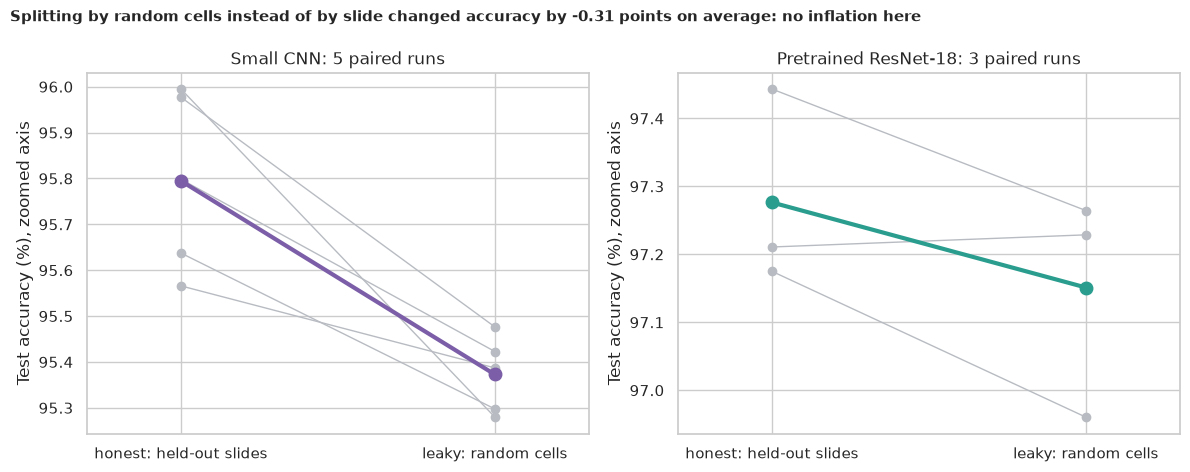

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, kind, title, color in [
    (axes[0], "small", "Small CNN", PURPLE),
    (axes[1], "resnet", "Pretrained ResNet-18", TEAL),
]:
    sub = leak[leak["model"] == kind]
    for _, r in sub.iterrows():
        ax.plot(
            [0, 1], [r["slide split"] * 100, r["random split"] * 100], color=GREY, marker="o", lw=1
        )
    ax.plot(
        [0, 1],
        [sub["slide split"].mean() * 100, sub["random split"].mean() * 100],
        color=color,
        marker="o",
        ms=9,
        lw=3,
    )
    ax.set_xticks([0, 1], ["honest: held-out slides", "leaky: random cells"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylabel("Test accuracy (%), zoomed axis")
    ax.set_title(f"{title}: {len(sub)} paired runs")
mean_gap = leak["inflation"].mean() * 100
fig.suptitle(
    f"Splitting by random cells instead of by slide changed accuracy by "
    f"{mean_gap:+.2f} points on average: no inflation here",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_leakage.png", dpi=150)
plt.show()

**How to read this:**

- **There is no sign of leakage inflation here:** the random split reads **0.31 points lower** on average, not higher: **-0.42** points for the small CNN (lower in all 5 pairs) and **-0.13** for ResNet (lower in 2 of 3 pairs). We **fail to reject H₀** for the one-sided hypothesis that random is higher; if anything, the held-out slides turned out slightly easier.
- **The sign test across the 8 pairs** (Wilcoxon p = 0.016) says the gap is consistently *negative*, but we should not make much of that: the two test sets are different cells, and a 0.3-point difference is about what we would expect from which slides land in the test set.
- **What this means:** unlike many medical-image datasets, the parasite itself is a strong enough signal that the networks do not need slide-specific shortcuts here. Splitting by slide is still the right thing to do (it cannot hurt and it is the question we care about), but on this dataset the legacy random split would not have misled us by much.
- A leak-free split is a cheap precaution, not proof of leakage: **always check**, rather than assume either way.

## 10. H5: how much data do we need?

*What:* the legacy notebook used 4,000 of the 27,558 images (2,000 per class) "for testing purposes". We train ResNet-18 on **500, 2,000, 8,000 and all 16,319** honest training cells (3 seeds each) and score every model on the same held-out slides. *Why:* collecting and labelling cells is expensive, so it is worth knowing where more data stops paying.

In [11]:
SIZES = [500, 2_000, 8_000, len(train_idx)]
size_rows = []
for n_train in SIZES:
    subset = np.random.default_rng(SEED).choice(train_idx, n_train, replace=False)
    for seed in range(N_SEEDS_RESNET):
        if n_train == len(train_idx):
            acc = model_results[
                (model_results["model"] == "resnet") & (model_results["seed"] == seed)
            ]
            size_rows.append({"cells": n_train, "seed": seed, "accuracy": acc["accuracy"].item()})
            continue
        model = train_cell_model("resnet", subset, seed)
        size_rows.append(
            {
                "cells": n_train,
                "seed": seed,
                "accuracy": summarise(score_cells(model, test_idx), test_idx)["accuracy"],
            }
        )
sizes = pd.DataFrame(size_rows)
size_summary = sizes.groupby("cells")["accuracy"].agg(["mean", "std", "min", "max"])
print((size_summary * 100).round(2).to_string())
legacy_subset = size_summary.loc[8_000, "mean"]
full = size_summary.loc[len(train_idx), "mean"]
print(f"\nFull training set vs {SIZES[2]:,} cells: {(full - legacy_subset) * 100:+.2f} points")

        mean   std    min    max
cells                           
500    95.10  0.08  95.01  95.17
2000   96.50  0.12  96.42  96.64
8000   97.11  0.11  96.98  97.19
16319  97.28  0.15  97.18  97.44

Full training set vs 8,000 cells: +0.17 points


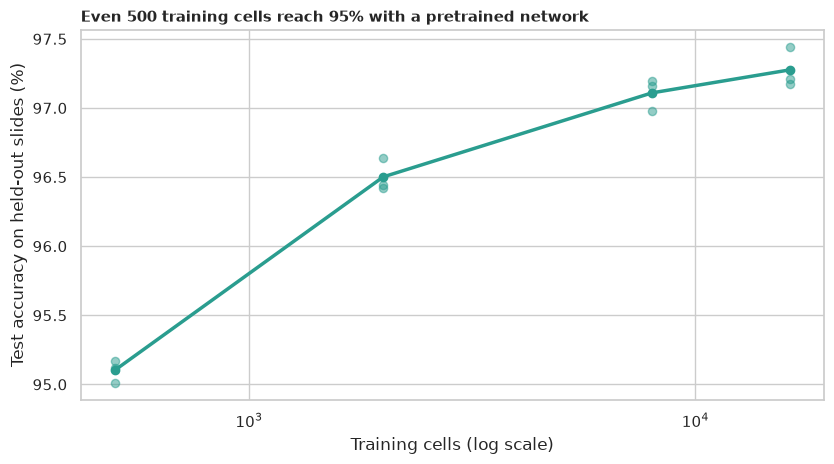

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for n, grp in sizes.groupby("cells"):
    ax.scatter(np.full(len(grp), n), grp["accuracy"] * 100, color=TEAL, alpha=0.5, s=35)
ax.plot(size_summary.index, size_summary["mean"] * 100, color=TEAL, marker="o", lw=2.5)
ax.set_xscale("log")
ax.set_xlabel("Training cells (log scale)")
ax.set_ylabel("Test accuracy on held-out slides (%)")
ax.set_title(
    f"Even {SIZES[0]} training cells reach {size_summary['mean'].iloc[0] * 100:.0f}% "
    "with a pretrained network",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_data_size.png", dpi=150)
plt.show()

**How to read this:**

- **Test accuracy rises with diminishing returns:** **95.10%** with 500 cells, **96.50%** with 2,000, **97.11%** with 8,000 and **97.28%** with all 16,319 training cells.
- **Even 500 cells are enough to beat the colour baseline** (93.2%) by about 1.9 points, thanks to pretraining; this is where a pretrained network earns its place.
- **Doubling the data twice more is hardly worth it:** going from 8,000 to all 16,319 cells adds only **0.17 points**, about the size of the run-to-run noise (standard deviation 0.11 to 0.15). The legacy notebook's 4,000-cell budget would have been enough for most of the benefit.

## 11. H6: choosing a threshold, and where it fails

*What:* a screening tool has to decide how many healthy cells it may wrongly flag. We set thresholds on the **validation** slides so that 90%, 95% or 99% of uninfected cells stay unflagged ("specificity"), and measure what share of parasitized cells (the "sensitivity") each threshold catches on the held-out test slides, with 95% Wilson intervals. Then we look at the error rate **slide by slide**: if the model fails evenly, every slide should have about the same error rate (chi-square test across the 42 test slides with at least 30 cells).

In [13]:
best_val = val_scores_store["resnet"]
best_test = test_scores[("resnet", 0)]
val_negative = best_val[labels[val_idx] == 0]
op_rows = []
for spec in (0.90, 0.95, 0.99):
    sens, low, high = sensitivity_at_specificity(y_test, best_test, val_negative, spec)
    flagged_healthy = (best_test[y_test == 0] > np.quantile(val_negative, spec)).mean()
    op_rows.append(
        {
            "target specificity": spec,
            "sensitivity": sens,
            "ci_low": low,
            "ci_high": high,
            "actual specificity on test": 1 - flagged_healthy,
        }
    )
operating = pd.DataFrame(op_rows).set_index("target specificity")
print(operating.round(3).to_string())

test_slides = pd.DataFrame({"slide": slides[test_idx], "wrong": (best_test > 0) != y_test})
slide_errors = test_slides.groupby("slide")["wrong"].agg(["size", "sum"])
big = slide_errors[slide_errors["size"] >= 30]
overall_error = test_slides["wrong"].mean()
chi = stats.chi2_contingency(np.column_stack([big["sum"], big["size"] - big["sum"]]))
slide_rate = big["sum"] / big["size"]
worst_slide = slide_rate.idxmax()
print(f"\n{len(big)} test slides with at least 30 cells; overall error rate {overall_error:.2%}")
print(
    f"Per-slide error rate: median {slide_rate.median():.2%}, worst {slide_rate.max():.2%} "
    f"({int(big.loc[worst_slide, 'sum'])} of {int(big.loc[worst_slide, 'size'])} cells)"
)
print(
    f"Is the error rate the same on every slide? chi-square({chi.dof}) = {chi.statistic:.0f}, "
    f"p = {fmt_p(chi.pvalue)}"
)

                    sensitivity  ci_low  ci_high  actual specificity on test
target specificity                                                          
0.90                      0.993   0.989    0.995                       0.913
0.95                      0.979   0.973    0.984                       0.957
0.99                      0.938   0.929    0.947                       0.992

42 test slides with at least 30 cells; overall error rate 2.79%
Per-slide error rate: median 1.70%, worst 8.96% (6 of 67 cells)
Is the error rate the same on every slide? chi-square(41) = 79, p = 3.2e-04


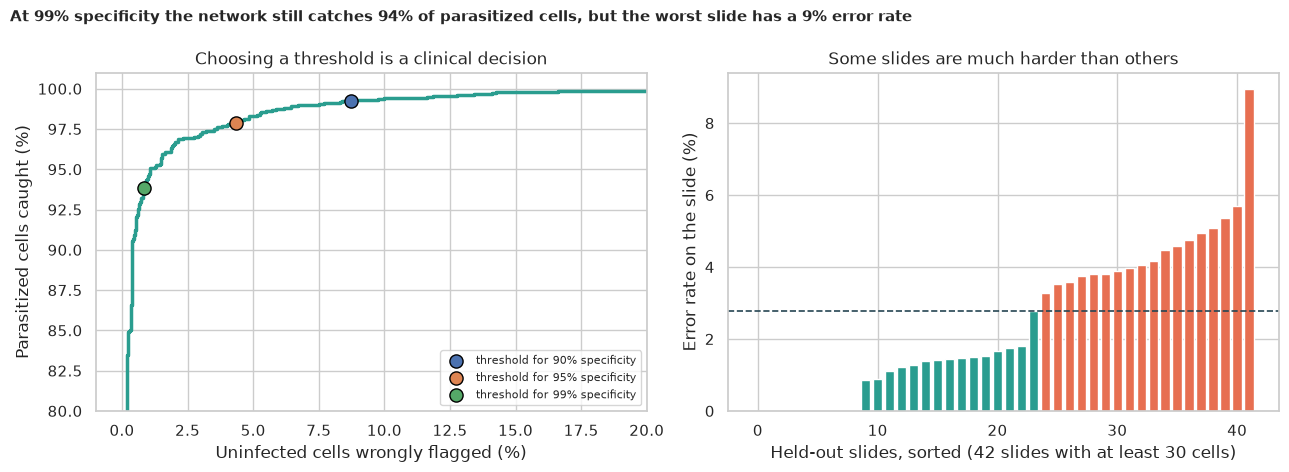

In [14]:
fpr, tpr, _ = roc_curve(y_test, best_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(fpr * 100, tpr * 100, color=TEAL, lw=2.5)
for spec, r in operating.iterrows():
    axes[0].scatter(
        (1 - r["actual specificity on test"]) * 100,
        r["sensitivity"] * 100,
        s=90,
        edgecolor="black",
        zorder=3,
        label=f"threshold for {spec:.0%} specificity",
    )
axes[0].set_xlabel("Uninfected cells wrongly flagged (%)")
axes[0].set_ylabel("Parasitized cells caught (%)")
axes[0].set_xlim(-1, 20)
axes[0].set_ylim(80, 101)
axes[0].set_title("Choosing a threshold is a clinical decision")
axes[0].legend(fontsize=8, loc="lower right")
rates = (slide_rate * 100).sort_values()
colors = np.where(rates > overall_error * 100, ORANGE, TEAL)
axes[1].bar(range(len(rates)), rates.to_numpy(), color=colors)
axes[1].axhline(overall_error * 100, color=NAVY, ls="--", lw=1.2)
axes[1].set_xlabel(f"Held-out slides, sorted ({len(rates)} slides with at least 30 cells)")
axes[1].set_ylabel("Error rate on the slide (%)")
axes[1].set_title("Some slides are much harder than others")
worst = rates.max()
fig.suptitle(
    f"At 99% specificity the network still catches {operating.loc[0.99, 'sensitivity']:.0%} "
    f"of parasitized cells, but the worst slide has a {worst:.0f}% error rate",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_operating_points.png", dpi=150)
plt.show()

**How to read this:**

- **The threshold is a trade-off, not a free parameter:** keeping specificity at 90% catches **99.3%** of parasitized cells (CI 98.9% to 99.5%); 95% specificity catches **97.9%** (97.3% to 98.4%); 99% specificity catches **93.8%** (92.9% to 94.7%). The specificities achieved on the test slides (91.3%, 95.7%, 99.2%) track the targets set on validation. Which point is right depends on the cost of a missed parasite against a wasted second look.
- **Errors cluster by slide:** the overall error rate is **2.79%**, but the median slide has **1.70%**, and the worst slide has **8.96%** (6 of 67 cells). The chi-square test across the 42 slides gives χ²(41) = 79, **p = 3e-4**, so **we reject H₀**: some slides are harder than others (different stain, focus or lighting).
- **What to do:** report results by slide, not just overall, and evaluate on slides from a new lab or camera before trusting any score.

## 12. 🎯 Takeaways

1. **Infected cells are darker in green** (Cliff's δ = -0.38), and there is no picture-size shortcut (area AUC 0.535).
2. **Colour statistics alone get 93.2%** (AUC 0.978): always build the simple baseline first.
3. **Networks beat it:** a small CNN reaches 95.79% and a pretrained ResNet-18 97.28% on slides it has never seen, and pretraining is worth about 1.5 points.
4. **The leaky split did not inflate the score here** (-0.31 points on average), but splitting by slide is the right default and the check was worth running.
5. **500 cells already reach 95.1%** with a pretrained network; all 16,319 add only 2.2 points more.
6. **The threshold is a clinical decision** (catching 93.8% to 99.3% of parasitized cells as specificity goes from 99% to 90%), and **errors cluster by slide** (1.7% median, 9.0% worst).

## 13. ⚠️ Limitations

- **One dataset from one lab.** The slides come from a single research study at one hospital in Bangladesh, with one microscope setup. A different stain, camera or species of parasite could lower every score.
- **Cells, not patients.** We split by slide, but a patient can contribute more than one slide; slides stand in for patients here, so a patient-level split would be stricter still.
- **Few seeds** (5 for the small CNN, 3 for ResNet): some p-values sit at their minimum possible value.
- **The leakage comparison uses two different test sets,** so differences of a few tenths of a point are within the noise it can add.
- **Images shrunk to 96 x 96 pixels** and a short, fixed training budget (12 epochs for the small CNN, 6 for ResNet); larger images and longer training would raise the scores.
- **Single cells are given, already segmented.** A real screening tool also has to find the cells in a full slide image.
- **Not a diagnostic device.** This is a teaching example; real diagnosis involves much more than cell classification.